In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

from xgboost import XGBRegressor
import joblib

In [27]:
data = pd.read_csv('train.csv')

In [28]:
data.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [29]:
test=pd.read_csv('test.csv')

In [30]:
test.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


In [31]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [32]:
data.duplicated().sum()

np.int64(0)

In [33]:
data.isna().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [34]:
data['Item_Weight'].fillna(data['Item_Weight'].median(), inplace=True)

/var/folders/d1/dh2cqpn53q78qb4gs2ydj0rr0000gn/T/ipykernel_90296/3976298003.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Item_Weight'].fillna(data['Item_Weight'].median(), inplace=True)


In [35]:
data['Outlet_Size'].fillna(data['Outlet_Size'].mode()[0], inplace=True)

/var/folders/d1/dh2cqpn53q78qb4gs2ydj0rr0000gn/T/ipykernel_90296/1434104270.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Outlet_Size'].fillna(data['Outlet_Size'].mode()[0], inplace=True)


In [36]:
data.isna().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [37]:
data.shape

(8523, 12)

In [38]:
data.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.00000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.81342,0.066132,140.992782,1997.831867,2181.288914
std,4.22724,0.051598,62.275067,8.371760,1706.499616
min,4.55500,0.000000,31.290000,1985.000000,33.290000
25%,9.31000,0.026989,93.826500,1987.000000,834.247400
50%,12.60000,0.053931,143.012800,1999.000000,1794.331000
75%,16.00000,0.094585,185.643700,2004.000000,3101.296400
max,21.35000,0.328391,266.888400,2009.000000,13086.964800


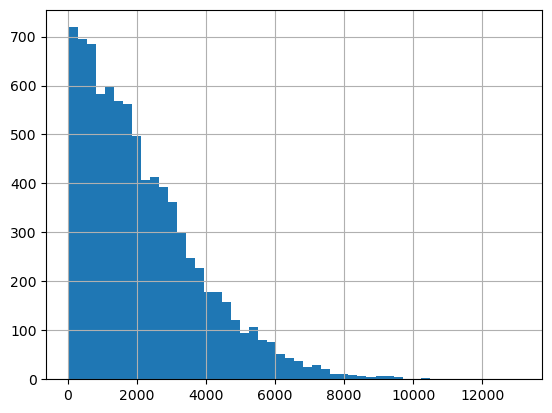

In [39]:
data['Item_Outlet_Sales'].hist(bins=50)
plt.show()

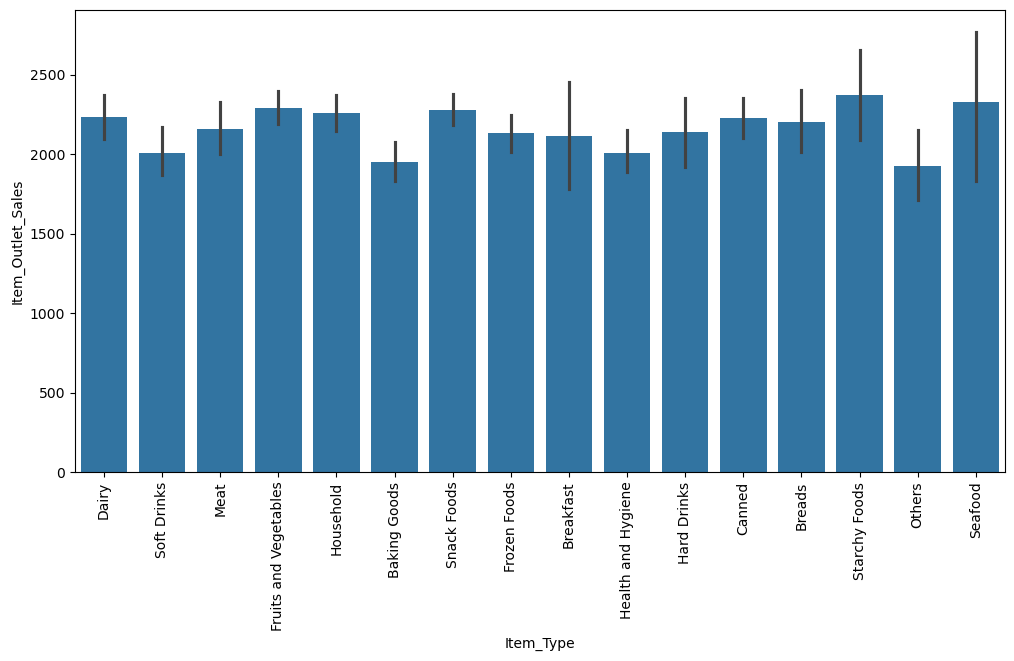

In [40]:
plt.figure(figsize=(12,6))

sns.barplot(
    x='Item_Type',
    y='Item_Outlet_Sales',
    data=data
)

plt.xticks(rotation=90)

plt.show()

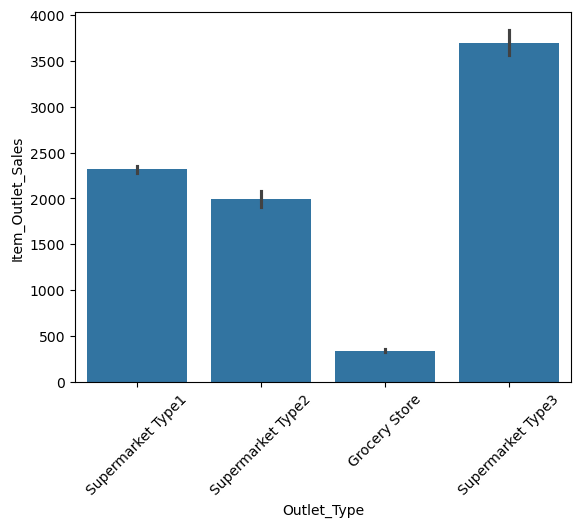

In [41]:
sns.barplot(
    x='Outlet_Type',
    y='Item_Outlet_Sales',
    data=data
)

plt.xticks(rotation=45)

plt.show()

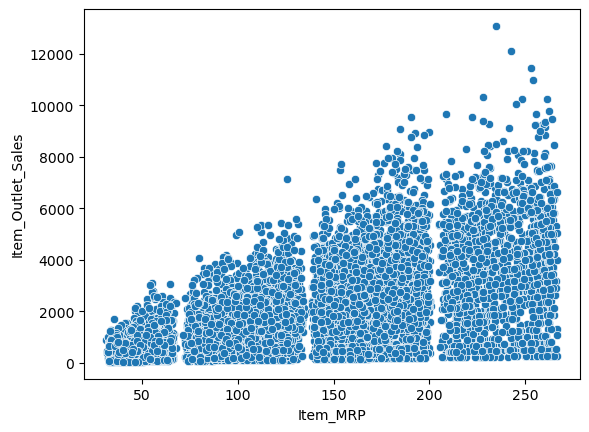

In [42]:
sns.scatterplot(
    x='Item_MRP',
    y='Item_Outlet_Sales',
    data=data
)

plt.show()

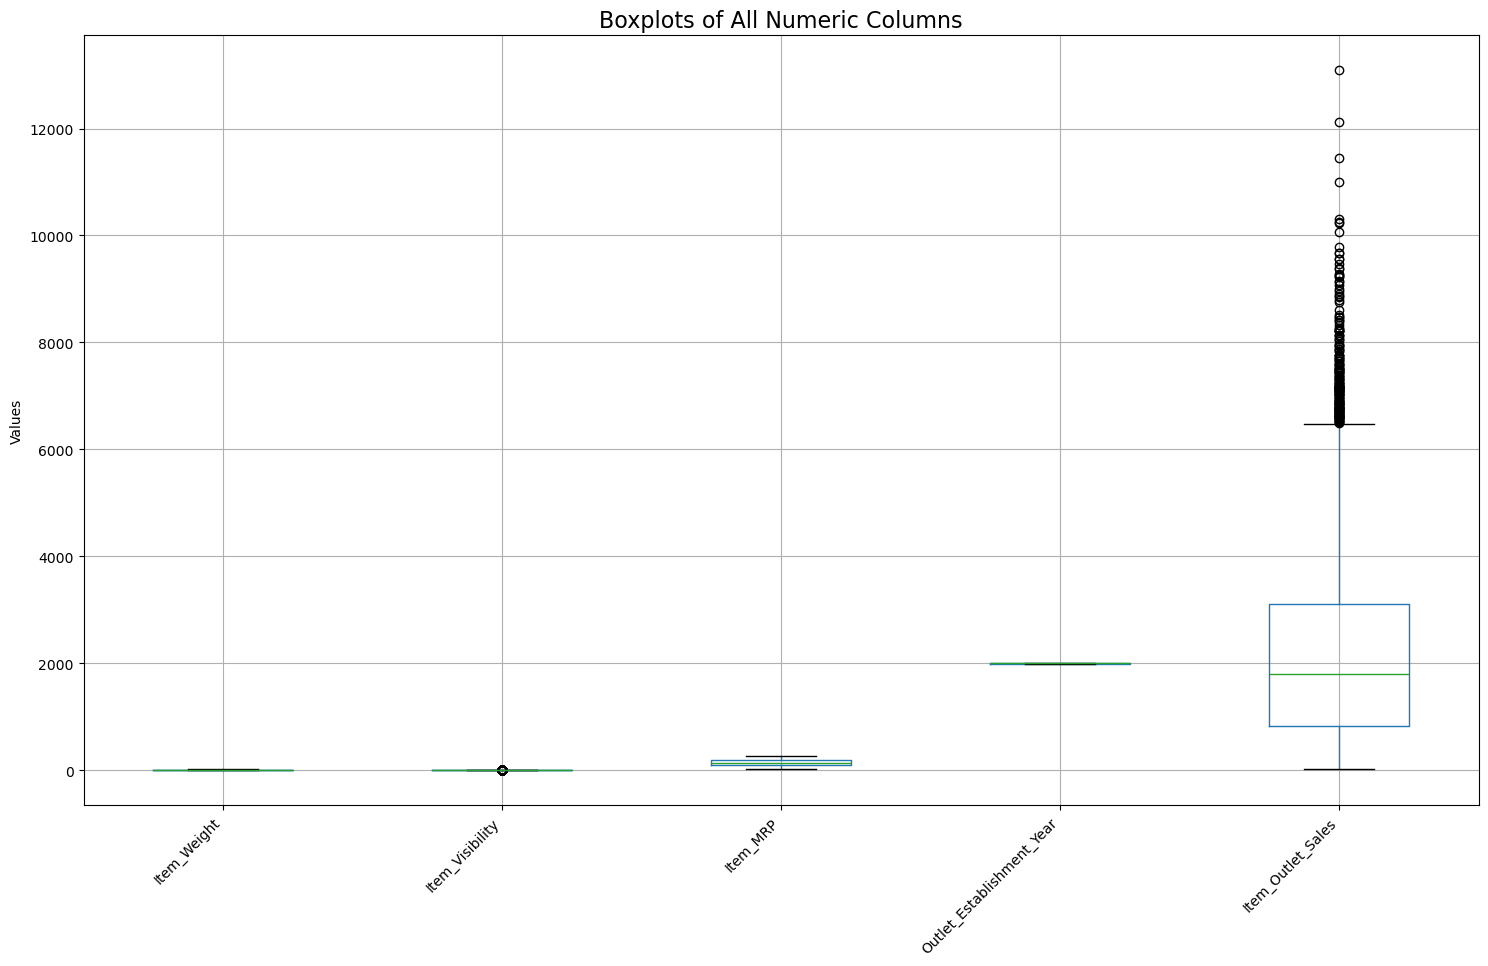

In [43]:
num_cols = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(18, 10))   
data[num_cols].boxplot()

plt.xticks(rotation=45, ha='right')  
plt.title("Boxplots of All Numeric Columns", fontsize=16)
plt.ylabel("Values")
plt.show()

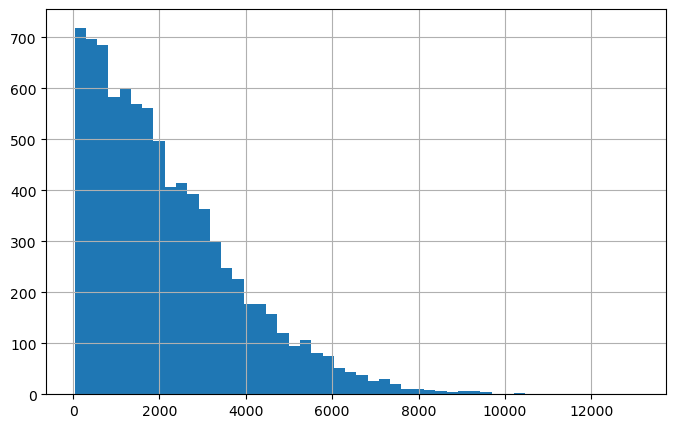

In [44]:
plt.figure(figsize=(8,5))
data['Item_Outlet_Sales'].hist(bins=50)

plt.show()

Before: 1.178
After: -0.882


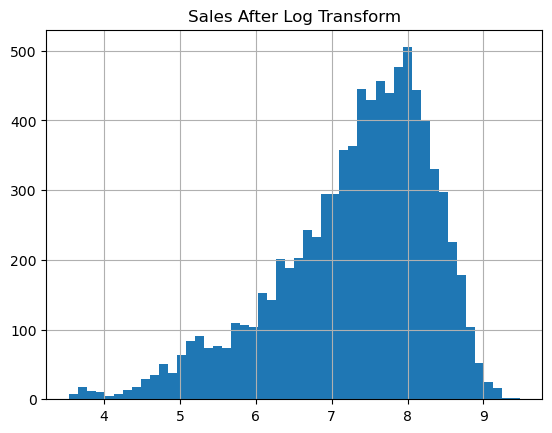

In [45]:
print("Before:", round(data["Item_Outlet_Sales"].skew(), 3))

data["Item_Outlet_Sales"] = np.log1p(data["Item_Outlet_Sales"])

print("After:", round(data["Item_Outlet_Sales"].skew(), 3))

data["Item_Outlet_Sales"].hist(bins=50)
plt.title("Sales After Log Transform")
plt.show()

In [46]:
data['Item_Fat_Content'] = data['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

test['Item_Fat_Content'] = test['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

print('Unique values after cleaning:', data['Item_Fat_Content'].unique())

Unique values after cleaning: ['Low Fat' 'Regular']


In [47]:
data.select_dtypes(include='object').columns

Index(['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier',
       'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type'],
      dtype='object')

In [48]:
test['Item_Weight'].fillna(test['Item_Weight'].median(), inplace=True)
test['Outlet_Size'].fillna(test['Outlet_Size'].mode()[0], inplace=True)



/var/folders/d1/dh2cqpn53q78qb4gs2ydj0rr0000gn/T/ipykernel_90296/3976644461.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test['Item_Weight'].fillna(test['Item_Weight'].median(), inplace=True)
/var/folders/d1/dh2cqpn53q78qb4gs2ydj0rr0000gn/T/ipykernel_90296/3976644461.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we a

In [49]:
for col in data.select_dtypes(include='object').columns:
    le = LabelEncoder()

    data[col] = le.fit_transform(data[col])
    test[col] = test[col].apply(lambda x: x if x in le.classes_ else le.classes_[0])
    test[col] = le.transform(test[col])

In [50]:
data['Outlet_Age'] = 2024 - data['Outlet_Establishment_Year']
test['Outlet_Age'] = 2024 - test['Outlet_Establishment_Year']

data['MRP_per_Visibility'] = data['Item_MRP'] / (data['Item_Visibility'] + 0.001)
test['MRP_per_Visibility'] = test['Item_MRP'] / (test['Item_Visibility'] + 0.001)

non_food = [6, 7, 8]
data['Is_Food_Item'] = data['Item_Type'].apply(lambda x: 0 if x in non_food else 1)
test['Is_Food_Item']  = test['Item_Type'].apply(lambda x: 0 if x in non_food else 1)

print('New features added: Outlet_Age, MRP_per_Visibility, Is_Food_Item')
print('Total features now:', data.drop('Item_Outlet_Sales', axis=1).shape[1])

New features added: Outlet_Age, MRP_per_Visibility, Is_Food_Item
Total features now: 14


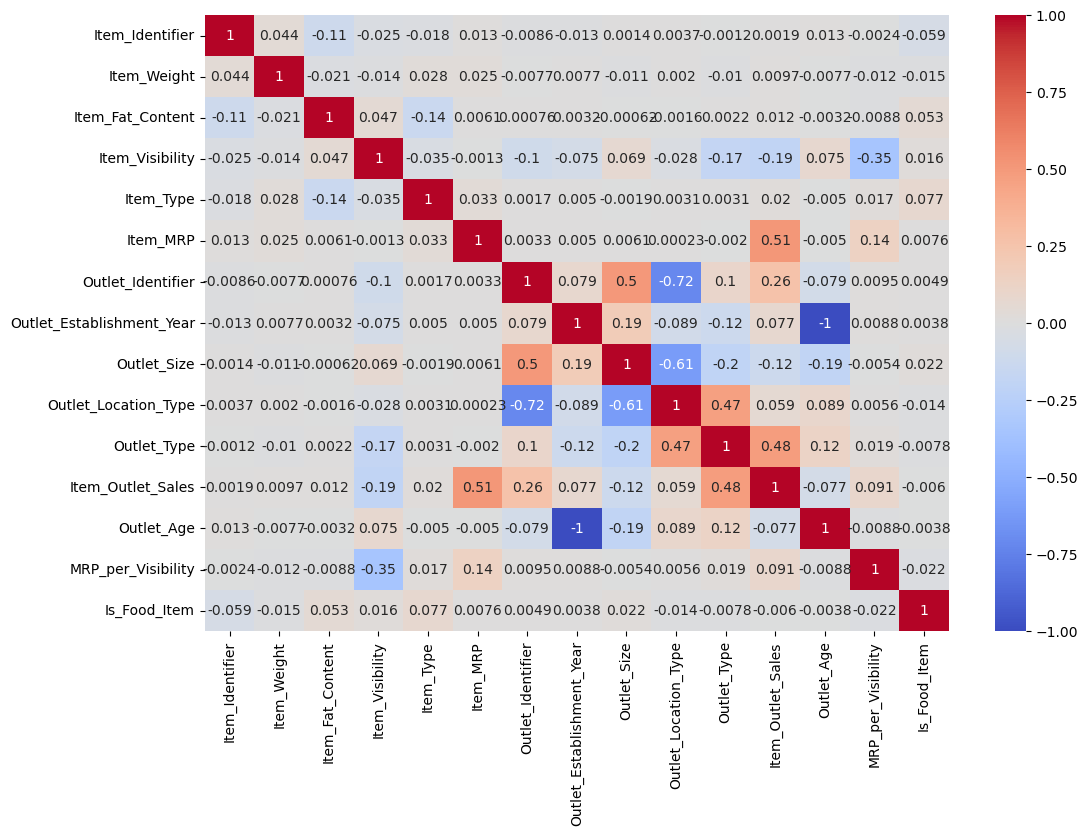

In [51]:
plt.figure(figsize=(12,8))

sns.heatmap(
    data.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [52]:
X = data.drop('Item_Outlet_Sales', axis=1)

In [53]:
y = data['Item_Outlet_Sales']

In [54]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [55]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_valid)

mae = mean_absolute_error(y_valid, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
r2 = r2_score(y_valid, y_pred)

lr_cv = cross_val_score(lr, X, y, cv=5, scoring='r2')

print('=== Linear Regression ===')
print(f'MAE:  {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2 Score (holdout): {r2:.4f}')
print(f'R2 Score (5-fold CV): {lr_cv.mean():.4f} ± {lr_cv.std():.4f}')

=== Linear Regression ===
MAE:  0.51
RMSE: 0.65
R2 Score (holdout): 0.6015
R2 Score (5-fold CV): 0.5921 ± 0.0167


In [56]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_valid)

mae = mean_absolute_error(y_valid, rf_pred)
rmse = np.sqrt(mean_squared_error(y_valid, rf_pred))
r2 = r2_score(y_valid, rf_pred)

rf_cv = cross_val_score(rf, X, y, cv=5, scoring='r2')

print('=== Random Forest ===')
print(f'MAE:  {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2 Score (holdout): {r2:.4f}')
print(f'R2 Score (5-fold CV): {rf_cv.mean():.4f} ± {rf_cv.std():.4f}')

=== Random Forest ===
MAE:  0.43
RMSE: 0.55
R2 Score (holdout): 0.7164
R2 Score (5-fold CV): 0.7010 ± 0.0128


In [57]:
param_dist = {
    'n_estimators':  [100, 200, 300, 400],
    'max_depth':     [3, 4, 5, 6, 7], 
    'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'subsample':     [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5]#controls tree splitting
}

xgb_base = XGBRegressor(random_state=42, verbosity=0)

search = RandomizedSearchCV(
    xgb_base,
    param_distributions=param_dist,
    n_iter=30,           
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print('Best Parameters:', search.best_params_)
print('Best CV R2 Score:', round(search.best_score_, 4))
print('Best Parameters:', search.best_params_)
print('Best CV R2 Score:', round(search.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'subsample': 0.6, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.9}
Best CV R2 Score: 0.7324
Best Parameters: {'subsample': 0.6, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.9}
Best CV R2 Score: 0.7324


In [58]:
xgb_best = search.best_estimator_
xgb_pred = xgb_best.predict(X_valid)
xgb_cv = cross_val_score(xgb_best, X, y, cv=5, scoring='r2')
id="simple_results"
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "XGBoost"],
    "R2": [
        r2_score(y_valid, y_pred),
        r2_score(y_valid, rf_pred),
        r2_score(y_valid, xgb_pred)
    ],
    "CV Mean": [
        lr_cv.mean(),
        rf_cv.mean(),
        xgb_cv.mean()
    ]
}).round(4)

print(results)

print("Best Model:", results.loc[results["CV Mean"].idxmax(), "Model"])

               Model      R2  CV Mean
0  Linear Regression  0.6015   0.5921
1      Random Forest  0.7164   0.7010
2            XGBoost  0.7411   0.7343
Best Model: XGBoost


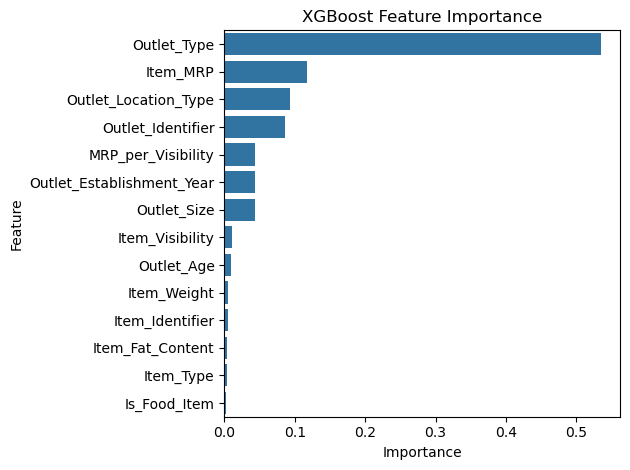

In [59]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_best.feature_importances_
}).sort_values(by='Importance', ascending=False)

sns.barplot(x='Importance', y='Feature', data=importance)
plt.title('XGBoost Feature Importance')
plt.tight_layout()
plt.show()

In [60]:
pred = xgb_best.predict(test)
pred = np.expm1(pred)
test["Predicted_Sales"] = pred

test.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Outlet_Age,MRP_per_Visibility,Is_Food_Item,Predicted_Sales
0,1114,20.750,0,0.007565,13,107.8622,9,1999,1,0,1,25,12593.609498,1,1522.393677
1,1078,8.300,1,0.038428,4,87.3198,2,2007,1,1,1,17,2214.682848,1,1273.456665
2,1420,14.600,0,0.099575,11,241.7538,0,1998,1,2,0,26,2403.718828,1,504.102539
3,817,7.315,0,0.015388,13,155.0340,2,2007,1,1,1,17,9459.987932,1,2204.673340
4,1197,12.500,1,0.118599,4,234.2300,5,1985,1,2,3,39,1958.456049,1,5100.191895


In [61]:
test.to_csv('sales_predictions.csv', index=False)
print('Saved to sales_predictions.csv')

Saved to sales_predictions.csv


In [62]:
future_data = pd.DataFrame({
    'Item_Identifier': [100],
    'Item_Weight': [12.5],
    'Item_Fat_Content': [0],   
    'Item_Visibility': [0.05],
    'Item_Type': [5],          
    'Item_MRP': [250],
    'Outlet_Identifier': [3],
    'Outlet_Establishment_Year': [2005],
    'Outlet_Size': [1],
    'Outlet_Location_Type': [2],
    'Outlet_Type': [1]
})

future_data['Outlet_Age'] = 2024 - future_data['Outlet_Establishment_Year']
future_data['MRP_per_Visibility'] = future_data['Item_MRP'] / (future_data['Item_Visibility'] + 0.001)

non_food = [6, 7, 8]  
future_data['Is_Food_Item'] = future_data['Item_Type'].apply(lambda x: 0 if x in non_food else 1)

future_pred_log = xgb_best.predict(future_data)
predicted_sales = np.expm1(future_pred_log)[0]

print(f'Predicted Sales: {predicted_sales:.2f}')

current_stock = 300

if predicted_sales > current_stock:
    print(f'  Stockout Risk — Predicted {predicted_sales:.0f} but only {current_stock} in stock')
elif predicted_sales < current_stock * 0.7:
    print(f' Overstock Risk — Predicted {predicted_sales:.0f}, excess stock: {current_stock - predicted_sales:.0f}')
else:
    print(f' Optimal Stock — Predicted {predicted_sales:.0f}, stock {current_stock}')

Predicted Sales: 3332.00
  Stockout Risk — Predicted 3332 but only 300 in stock


In [63]:
joblib.dump(xgb_best, 'retail_sales_model.pkl')
print('Model saved.')

loaded_model = joblib.load('retail_sales_model.pkl')
print('Model loaded successfully.')

Model saved.
Model loaded successfully.
